Q2- Adam Elmalek TEAM_MEMBER_1_ID Mohammed younis TEAM_MEMBER_2_ID
https://drive.google.com/drive/folders/1hjwPLAveMOwNfOOHQ6fQk2jkyS0dIEGd?usp=drive_link

## Cell 0 — Mount & Paths (Drive-first as required)

In [ ]:

## חיבור ל-Drive והגדרת נתיבי בסיס
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

BASE = '/content/drive/MyDrive/airbnb_adam_mohammed'  ## עדכנו אם צריך
DOCS = f'{BASE}/docs'
DATA_RAW = f'{BASE}/data_raw'
DATA_CLEAN = f'{BASE}/data_clean'
FIG_DIR = f'{BASE}/outputs/figures'

import os
for p in [DOCS, DATA_RAW, DATA_CLEAN, FIG_DIR]:
    os.makedirs(p, exist_ok=True)

print("BASE:", BASE)


Mounted at /content/drive
BASE: /content/drive/MyDrive/airbnb_adam_mohammed


## Cell 1 — טעינת נתונים (from Q1)

In [ ]:

## טעינת שם העיר מתוך docs/selected_city.txt
CITY = None
sel_path = f'{DOCS}/selected_city.txt'
try:
    with open(sel_path, 'r', encoding='utf-8') as f:
        CITY = f.read().strip()
except FileNotFoundError:
    CITY = input("selected_city.txt not found — type the city name (e.g., 'New York City'): ").strip()
print("CITY:", CITY if CITY else "(none)")


CITY: New York City


## Cell 2 — טעינת נתונים

In [ ]:

## טעינת הנתונים
import pandas as pd
import numpy as np
import os

RAW_CSV = f'{DATA_RAW}/listings.csv'
RAW_GZ  = f'{DATA_RAW}/listings.csv.gz'
path = RAW_CSV if os.path.exists(RAW_CSV) else (RAW_GZ if os.path.exists(RAW_GZ) else None)
if path is None:
    raise FileNotFoundError(f"Place listings.csv or listings.csv.gz under {DATA_RAW} and re-run.")

df = pd.read_csv(path, low_memory=False)
print("Shape (rows, cols):", df.shape)
print("First columns:", list(df.columns[:15]))
display(df.head(5)); display(df.tail(3))


Shape (rows, cols): (36322, 18)
First columns: ['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count']


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,2539,Superfast Wi-Fi. Clean & quiet home by the park,2787,John,Brooklyn,Kensington,40.64529,-73.97238,Private room,285.0,30,9,2018-10-19,0.08,6,347,0,NaN
1,2595,Skylit Midtown Manhattan Spacious Studio,2845,Jennifer,Manhattan,Midtown,40.75356,-73.98559,Entire home/apt,240.0,30,49,2022-06-21,0.26,3,312,0,NaN
2,5136,Spacious Family Friendly Duplex w/ Patio + Yard,7378,Rebecca,Brooklyn,Sunset Park,40.66265,-73.99454,Entire home/apt,215.0,30,4,2023-08-20,0.03,1,80,0,NaN
3,6848,Only 2 stops to Manhattan studio,15991,Allen,Brooklyn,Williamsburg,40.70935,-73.95342,Entire home/apt,97.0,30,196,2025-06-09,1.00,1,219,4,NaN
4,6872,Uptown Sanctuary w/ Private Bath (Month to Month),16104,Kahshanna,Manhattan,East Harlem,40.80107,-73.94255,Private room,NaN,30,1,2022-06-05,0.03,2,2,0,NaN


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
36319,1437716663281487811,Beautiful 1-bedroom Apartment,247439246,Charlene,Manhattan,Upper East Side,40.763030,-73.962800,Entire home/apt,259.0,30,0,NaN,NaN,9,320,0,NaN
36320,1437717590842865352,Spacious Comfort Beach-Walk,699701332,Adepeju,Queens,Arverne,40.592956,-73.797732,Private room,67.0,30,0,NaN,NaN,1,365,0,NaN
36321,1437874319735048027,Room in prime Hells Kitchen spot,663472167,Omar,Manhattan,Hell's Kitchen,40.758430,-73.991650,Private room,101.0,30,0,NaN,NaN,7,260,0,NaN


## Cell 3 — Dtypes, basic stats, unique values

In [ ]:

## טיפוסים וסטטיסטיקות
print("\nDtypes:"); print(df.dtypes)

print("\nNumeric describe:")
display(df.describe(include=[np.number]).T)

## ייחודיות לדוגמה (עד 20 עמודות ראשונות)
sample_cols = list(df.columns[:20])
summary_unique = []
for c in sample_cols:
    try:
        nunique = df[c].nunique(dropna=False)
    except Exception:
        nunique = None
    summary_unique.append((c, nunique))
print("\nUnique counts (first 20 cols):")
for name, nu in summary_unique:
    print(f"- {name}: {nu}")



Dtypes:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                             float64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
number_of_reviews_ltm               int64
license                            object
dtype: object

Numeric describe:


,count,mean,std,min,25%,50%,75%,max
id,36322.0,4.382216e+17,5.199100e+17,2539.000000,2.121091e+07,5.004978e+07,9.277467e+17,1.444534e+18
host_id,36322.0,1.713590e+08,1.893709e+08,1678.000000,1.764159e+07,8.336440e+07,3.036223e+08,7.005911e+08
latitude,36322.0,4.072856e+01,5.648223e-02,40.500366,4.068828e+01,4.072594e+01,4.076235e+01,4.091139e+01
longitude,36322.0,-7.394697e+01,5.525153e-02,-74.251907,-7.398326e+01,-7.395471e+01,-7.392785e+01,-7.371182e+01
price,21459.0,5.215284e+02,3.501385e+03,8.000000,8.900000e+01,1.540000e+02,2.700000e+02,5.018400e+04
minimum_nights,36322.0,2.920572e+01,3.511100e+01,1.000000,3.000000e+01,3.000000e+01,3.000000e+01,1.124000e+03
number_of_reviews,36322.0,2.685304e+01,6.738206e+01,0.000000,0.000000e+00,3.000000e+00,2.300000e+01,3.277000e+03
reviews_per_month,25171.0,8.172615e-01,1.850794e+00,0.010000,8.000000e-02,2.600000e-01,9.400000e-01,1.219700e+02
calculated_host_listings_count,36322.0,6.070415e+01,1.950884e+02,1.000000,1.000000e+00,1.000000e+00,8.000000e+00,1.054000e+03
availability_365,36322.0,1.590105e+02,1.455351e+02,0.000000,0.000000e+00,1.530000e+02,3.100000e+02,3.650000e+02



Unique counts (first 20 cols):
- id: 36322
- name: 34733
- host_id: 21795
- host_name: 8377
- neighbourhood_group: 5
- neighbourhood: 223
- latitude: 22551
- longitude: 20416
- room_type: 4
- price: 1102
- minimum_nights: 121
- number_of_reviews: 500
- last_review: 3323
- reviews_per_month: 783
- calculated_host_listings_count: 68
- availability_365: 366
- number_of_reviews_ltm: 176
- license: 1964


## Cell 4 — Rename at least 2 categorical columns + identify numeric/categorical

In [ ]:

## שינוי שמות לעמודות כדי שיהיו מובנות יותר (דוגמה; עדכנו לפי הנתונים שלכם)
rename_map = {}
if 'neighbourhood_cleansed' in df.columns: rename_map['neighbourhood_cleansed'] = 'neighbourhood'
if 'calculated_host_listings_count' in df.columns: rename_map['calculated_host_listings_count'] = 'host_listings_count'

if rename_map:
    df = df.rename(columns=rename_map)
    print("Renamed columns:", rename_map)

## זיהוי סוגי משתנים (פשוט): מספריים/קטגוריים
import numpy as np
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
print("Numeric columns (head):", num_cols[:10])
print("Categorical columns (head):", cat_cols[:10])


Renamed columns: {'calculated_host_listings_count': 'host_listings_count'}
Numeric columns (head): ['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'host_listings_count', 'availability_365']
Categorical columns (head): ['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review', 'license']


## Cell 5 — Cleaning plan (missing, types, duplicates, impossible values)

In [ ]:

## טבלת חסרים + אסטרטגיית טיפול
def missing_table(d):
    miss = d.isna().sum().sort_values(ascending=False)
    pct = (miss / len(d)) * 100
    out = pd.DataFrame({'missing': miss, 'missing_%': pct.round(2)})
    return out[out['missing']>0]

mt = missing_table(df)
print("Missing values (top 30):")
display(mt.head(30))

## המרות מחיר (מחרוזת → מספר)
for col in ['price','weekly_price','monthly_price','security_deposit','cleaning_fee']:
    if col in df.columns:
        df[col] = (df[col].astype(str)
                          .str.replace('$','',regex=False)
                          .str.replace(',','',regex=False)
                          .replace('nan', np.nan))
        df[col] = pd.to_numeric(df[col], errors='coerce')

## המרות תאריך
for col in ['last_review','first_review','host_since','calendar_last_scraped']:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

## טיפול חסרים: מילוי ממוצע לעמודות מספריות (פשוט) + השארת טקסטואליות כמו שהן
num_cols = df.select_dtypes(include=[np.number]).columns
if len(num_cols) > 0:
    df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

## הסרת כפילויות (עדיפות לפי 'id')
if 'id' in df.columns:
    before = len(df); df = df.drop_duplicates(subset=['id']); after = len(df)
    print("Removed duplicates by id:", before - after)
else:
    df = df.drop_duplicates()

## בדיקת ערכים לא הגיוניים (דוגמאות): מחירים שליליים, לילות מינימום שליליים
if 'price' in df.columns:
    neg_price = (df['price'] < 0).sum()
    if neg_price > 0:
        print("Found negative prices -> setting to NaN then filling with mean.")
        df.loc[df['price'] < 0, 'price'] = np.nan
        df['price'] = df['price'].fillna(df['price'].mean())

if 'minimum_nights' in df.columns:
    neg_min = (df['minimum_nights'] < 0).sum()
    if neg_min > 0:
        print("Found negative minimum_nights -> set to abs.")
        df['minimum_nights'] = df['minimum_nights'].abs()

print("Shape after basic cleaning:", df.shape)


Missing values (top 30):


,missing,missing_%
license,30993,85.33
price,14863,40.92
reviews_per_month,11151,30.70
last_review,11151,30.70
host_name,15,0.04
name,2,0.01


Removed duplicates by id: 0
Shape after basic cleaning: (36322, 18)


## Cell 6 — Outliers detection & handling (price, Z-score>3)

In [ ]:

## חריגים במחיר: Z-score > 3 — הסרה פשוטה (לפי הסילבוס)
if 'price' in df.columns and df['price'].std() and df['price'].std() > 0:
    z = (df['price'] - df['price'].mean()) / df['price'].std()
    before = len(df)
    df = df[np.abs(z) < 3]
    print("Removed outliers by price Z-score>3:", before - len(df))
else:
    print("No price std or column missing; skip outlier removal.")


Removed outliers by price Z-score>3: 158


## Cell 7 —  (price bins, host experience, +2 custom)

In [ ]:

## הנדסת תכונות פשוטה
import numpy as np
from pandas.api.types import is_datetime64_any_dtype as is_dt

# 1) price_category: זול/בינוני/יקר לפי חיתוכים של קוורטילים
if 'price' in df.columns:
    q = df['price'].quantile([0.33, 0.66]).values if df['price'].notna().any() else [0,0]
    def price_bin(p):
        if np.isnan(p): return 'Unknown'
        if p <= q[0]: return 'Low'
        if p <= q[1]: return 'Medium'
        return 'High'
    df['price_category'] = df['price'].apply(price_bin)

# 2) host_experience_years: אם יש host_since -> שנים ניסיון; אחרת 'Unknown'
if 'host_since' in df.columns and is_dt(df['host_since']):
    ref = df['host_since'].max() if df['host_since'].notna().any() else pd.Timestamp.today()
    df['host_experience_years'] = (ref.year - df['host_since'].dt.year).fillna(0).clip(lower=0)
else:
    df['host_experience_years'] = np.nan

# 3) reviews_intensity: מספר ביקורות לחודש (אם יש)
if 'number_of_reviews' in df.columns:
    if 'reviews_per_month' in df.columns:
        df['reviews_intensity'] = df['reviews_per_month'].fillna(0)
    else:
        df['reviews_intensity'] = df['number_of_reviews'] / 12.0

# 4) is_long_min_stay: שהות מינימלית ארוכה (>=7)
if 'minimum_nights' in df.columns:
    df['is_long_min_stay'] = (df['minimum_nights'] >= 7).astype(int)

print("Engineered columns:", [c for c in ['price_category','host_experience_years','reviews_intensity','is_long_min_stay'] if c in df.columns])


Engineered columns: ['price_category', 'host_experience_years', 'reviews_intensity', 'is_long_min_stay']


## Cell 8 — EDA:  (numeric) + categorical

Saved: /content/drive/MyDrive/airbnb_adam_mohammed/outputs/figures/price_hist.png


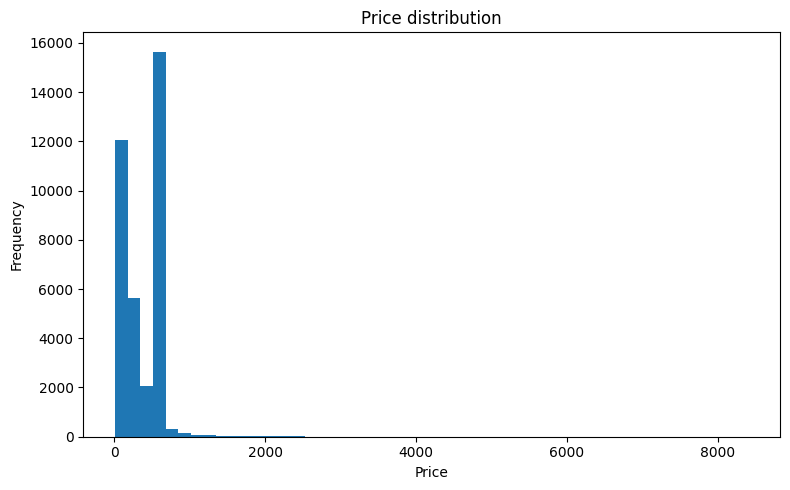

Saved: /content/drive/MyDrive/airbnb_adam_mohammed/outputs/figures/room_type_bar.png


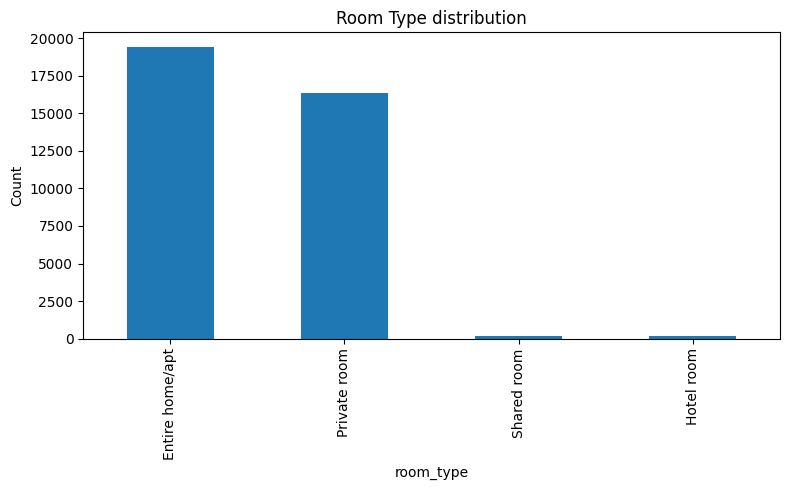

Saved: /content/drive/MyDrive/airbnb_adam_mohammed/outputs/figures/top10_neighbourhood.png


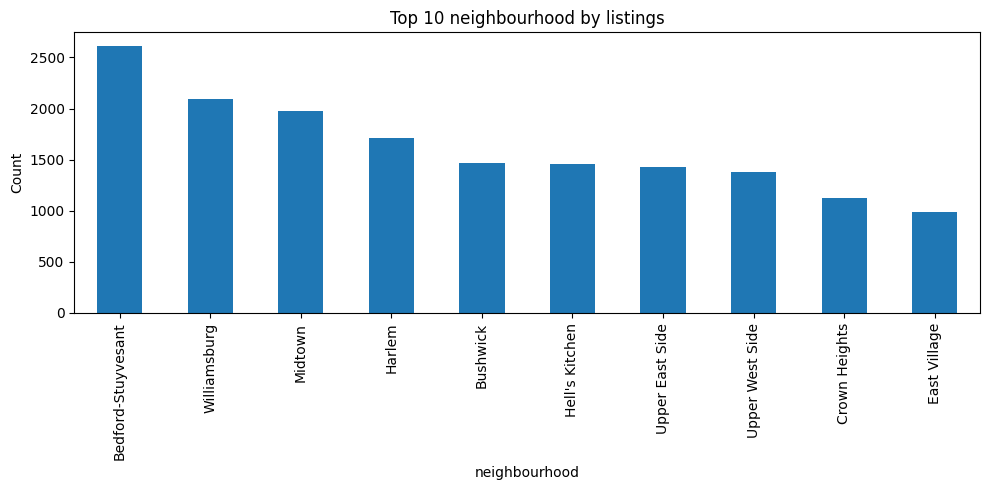

In [ ]:

## הצגות בסיסיות — לשמור תמונות ל-FIG_DIR
import matplotlib.pyplot as plt
import seaborn as sns
import os

def save_show(fig_path):
    plt.tight_layout(); plt.savefig(fig_path, bbox_inches='tight'); print("Saved:", fig_path); plt.show()

# Numeric distribution: price
if 'price' in df.columns:
    plt.figure(figsize=(8,5))
    df['price'].dropna().plot(kind='hist', bins=50)
    plt.title('Price distribution'); plt.xlabel('Price'); plt.ylabel('Frequency')
    save_show(f'{FIG_DIR}/price_hist.png')

# Categorical: room_type
if 'room_type' in df.columns:
    plt.figure(figsize=(8,5))
    df['room_type'].value_counts(dropna=False).plot(kind='bar')
    plt.title('Room Type distribution'); plt.xlabel('room_type'); plt.ylabel('Count')
    save_show(f'{FIG_DIR}/room_type_bar.png')

# Top neighbourhoods
neigh_cols = [c for c in ['neighbourhood','neighbourhood_cleansed'] if c in df.columns]
if neigh_cols:
    col = neigh_cols[0]
    topn = (df[col].astype(str).str.strip()
             .replace({'nan': np.nan})
             .value_counts(dropna=True).head(10))
    plt.figure(figsize=(10,5))
    topn.plot(kind='bar')
    plt.title(f'Top 10 {col} by listings'); plt.xlabel(col); plt.ylabel('Count')
    save_show(f'{FIG_DIR}/top10_{col}.png')


## Cell 9 — Bivariate: price vs location / room_type / reviews

Saved: /content/drive/MyDrive/airbnb_adam_mohammed/outputs/figures/price_by_neighbourhood_box.png


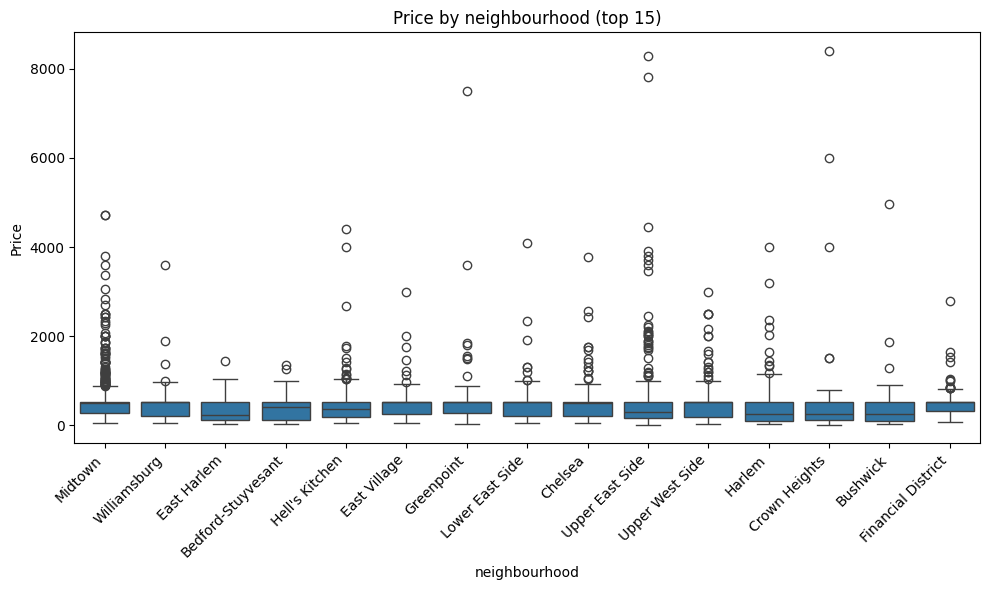

Saved: /content/drive/MyDrive/airbnb_adam_mohammed/outputs/figures/price_by_room_type_box.png


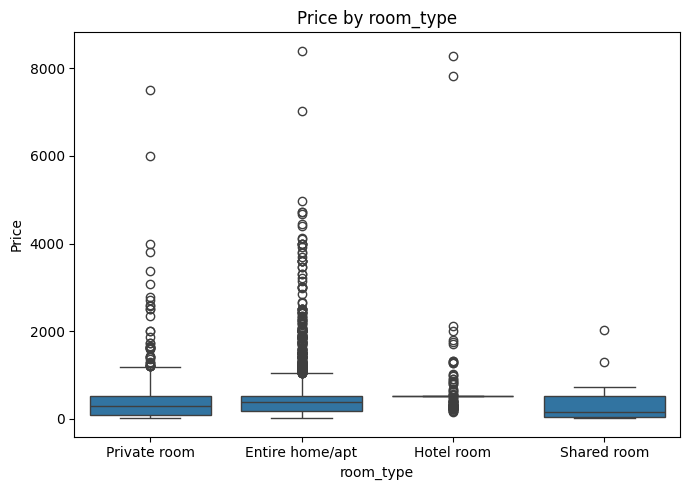

Saved: /content/drive/MyDrive/airbnb_adam_mohammed/outputs/figures/price_vs_reviews_scatter.png


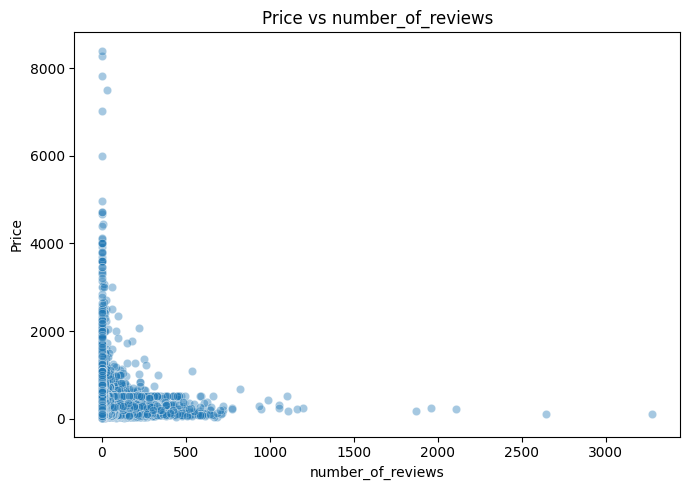

In [ ]:

## קשרים בין משתנים
import seaborn as sns
import matplotlib.pyplot as plt

# price vs neighbourhood (top 15 by count)
neigh_cols = [c for c in ['neighbourhood','neighbourhood_cleansed'] if c in df.columns]
if 'price' in df.columns and neigh_cols:
    col = neigh_cols[0]
    top15 = df[col].value_counts().head(15).index
    tmp = df[df[col].isin(top15)]
    plt.figure(figsize=(10,6))
    sns.boxplot(data=tmp, x=col, y='price')
    plt.xticks(rotation=45, ha='right')
    plt.title('Price by neighbourhood (top 15)'); plt.xlabel(col); plt.ylabel('Price')
    save_show(f'{FIG_DIR}/price_by_neighbourhood_box.png')

# price vs room_type
if 'price' in df.columns and 'room_type' in df.columns:
    plt.figure(figsize=(7,5))
    sns.boxplot(data=df, x='room_type', y='price')
    plt.title('Price by room_type'); plt.xlabel('room_type'); plt.ylabel('Price')
    save_show(f'{FIG_DIR}/price_by_room_type_box.png')


if 'price' in df.columns and 'number_of_reviews' in df.columns:
    plt.figure(figsize=(7,5))
    sns.scatterplot(data=df, x='number_of_reviews', y='price', alpha=0.4)
    plt.title('Price vs number_of_reviews'); plt.xlabel('number_of_reviews'); plt.ylabel('Price')
    save_show(f'{FIG_DIR}/price_vs_reviews_scatter.png')


## Cell 10 — Inactive listings (no review ≥24 months)

Inactive (24m) listings: 21827
Saved: /content/drive/MyDrive/airbnb_adam_mohammed/outputs/figures/inactive_rate_by_neighbourhood.png


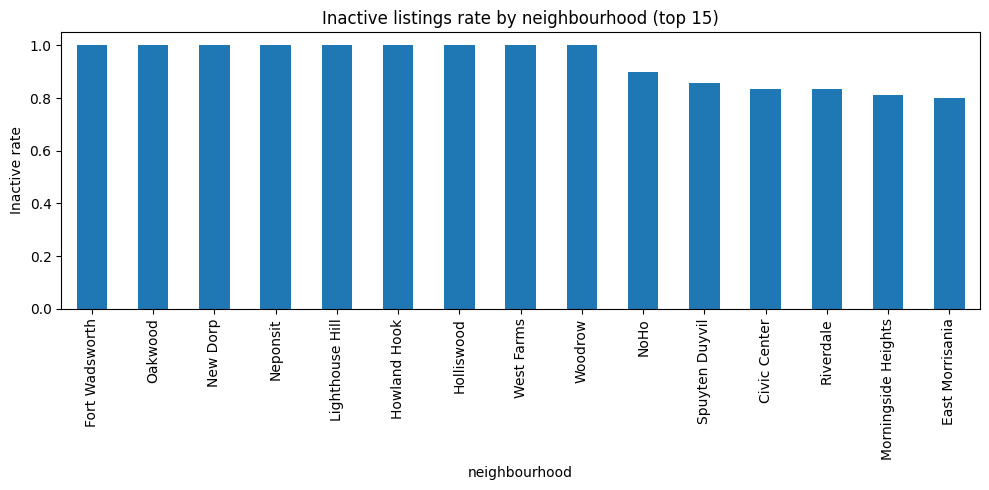

In [ ]:

## סימון לא פעיל לשנתיים
ref = None
if 'calendar_last_scraped' in df.columns and pd.notna(df['calendar_last_scraped']).any():
    ref = pd.to_datetime(df['calendar_last_scraped']).max()
else:
    ref = pd.Timestamp.today()

date_col = None
for cand in ['last_review','first_review']:
    if cand in df.columns:
        date_col = cand; break

if date_col:
    two_years_days = 365*2
    inactive_mask = (df[date_col].isna()) | ((ref - df[date_col]).dt.days > two_years_days)
    df['inactive_2y'] = inactive_mask.astype(int)
    print("Inactive (24m) listings:", int(df['inactive_2y'].sum()))

# inactive rate by neighbourhood
neigh_cols = [c for c in ['neighbourhood','neighbourhood_cleansed'] if c in df.columns]
if neigh_cols and 'inactive_2y' in df.columns:
    col = neigh_cols[0]
    rate = df.groupby(col)['inactive_2y'].mean().sort_values(ascending=False).head(15)
    plt.figure(figsize=(10,5))
    rate.plot(kind='bar')
    plt.title('Inactive listings rate by neighbourhood (top 15)'); plt.xlabel(col); plt.ylabel('Inactive rate')
    save_show(f'{FIG_DIR}/inactive_rate_by_neighbourhood.png')




```
# This is formatted as code
```

## Cell 11 — Grouped summaries (host top-20, price summaries)

In [ ]:

## טבלאות סיכום
# Top 20 hosts by number of listings
if 'host_id' in df.columns:
    top_hosts = df['host_id'].value_counts().head(20)
    print("Top 20 hosts by listing count:")
    display(top_hosts)

# Price stats by neighbourhood/room_type
group_cols = []
if 'neighbourhood' in df.columns: group_cols.append('neighbourhood')
if 'room_type' in df.columns: group_cols.append('room_type')
if 'price' in df.columns and group_cols:
    g = (df.groupby(group_cols)['price'].agg(['count','median','mean'])
           .sort_values(by='count', ascending=False))
    display(g.head(30))


Top 20 hosts by listing count:


,count
host_id,
107434423,1054
3223938,592
446820235,330
533234561,280
19303369,254
162280872,237
200239515,231
204704622,215
51501835,180


,,count,median,mean
neighbourhood,room_type,,,
Bedford-Stuyvesant,Private room,1531,521.528356,334.009939
Midtown,Entire home/apt,1202,436.500000,455.727307
Upper East Side,Entire home/apt,1201,300.000000,375.929541
Williamsburg,Entire home/apt,1084,521.528356,420.637764
Bedford-Stuyvesant,Entire home/apt,1056,269.000000,330.318453
Hell's Kitchen,Entire home/apt,1021,350.000000,373.054716
Bushwick,Private room,1013,290.000000,300.543583
Williamsburg,Private room,989,521.528356,374.895850
Harlem,Private room,953,135.000000,268.914156


## Cell 12 — Hypotheses

In [ ]:

## בדיקת השערות ברמה תיאורית (ללא מבחנים סטטיסטיים מתקדמים)
import numpy as np

# H1: Entire home/apartment more expensive than private/shared
if 'room_type' in df.columns and 'price' in df.columns:
    means = df.groupby('room_type')['price'].mean().sort_values(ascending=False)
    print("Average price by room_type:")
    print(means)

# H2: More reviews -> higher availability (correlation direction)
if all(c in df.columns for c in ['number_of_reviews','availability_365']):
    corr = df[['number_of_reviews','availability_365']].corr().iloc[0,1]
    print(f"Correlation number_of_reviews vs availability_365: {corr:.3f}")

# H3: Host listing count influences price
if all(c in df.columns for c in ['host_listings_count','price']):
    corr2 = df[['host_listings_count','price']].corr().iloc[0,1]
    print(f"Correlation host_listings_count vs price: {corr2:.3f}")


Average price by room_type:
room_type
Hotel room         624.723726
Entire home/apt    376.065714
Private room       312.561031
Shared room        259.164425
Name: price, dtype: float64
Correlation number_of_reviews vs availability_365: 0.075
Correlation host_listings_count vs price: 0.057


## Cell 13 — Save cleaned data & mini executive summary

In [ ]:

## שמירה + סיכום
out_csv = f'{DATA_CLEAN}/listings_clean.csv'
df.to_csv(out_csv, index=False)
print("Saved cleaned file:", out_csv)

print("\nExecutive Summary:")
print(f"- City: {CITY}")
print(f"- Rows (after cleaning): {len(df)}")
if 'price' in df.columns:
    print(f"- Avg price: ${df['price'].mean():.2f}")
print("- See figures in outputs/figures and use them in your slides/report.")


Saved cleaned file: /content/drive/MyDrive/airbnb_adam_mohammed/data_clean/listings_clean.csv

Executive Summary:
- City: New York City
- Rows (after cleaning): 36164
- Avg price: $348.05
- See figures in outputs/figures and use them in your slides/report.


## Cell 14 (Optional Bonus) — Merge `host_since` from external detailed file

In [ ]:

## איחוד עמודת host_since מתוך קובץ מפורט (אם הורדתם זיפ נוסף)
# 1) שימו את הקובץ המפורט (CSV) בתיקייה data_raw/ בשם listings_detailed.csv
# 2) הפעילו את התא
import os
detailed_path = f'{DATA_RAW}/listings_detailed.csv'
if os.path.exists(detailed_path):
    det = pd.read_csv(detailed_path, low_memory=False)
    key = 'id' if 'id' in df.columns and 'id' in det.columns else None
    if key and 'host_since' in det.columns:
        det['host_since'] = pd.to_datetime(det['host_since'], errors='coerce')
        before_cols = set(df.columns)
        df = df.merge(det[['id','host_since']], on='id', how='left', suffixes=('','_det'))
        print("Merged host_since from detailed file.")
        # Recompute host_experience_years
        if df['host_since'].notna().any():
            ref = df['host_since'].max()
            df['host_year'] = df['host_since'].dt.year
            yearly = df.groupby('host_year').size().rename('new_listings')
            display(yearly.head(20))
else:
    print("No detailed file found — skip.")


No detailed file found — skip.
